In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

tr = np.loadtxt("train.csv", delimiter=",", skiprows=1)
va = np.loadtxt("val.csv", delimiter=",", skiprows=1)
X_test = np.loadtxt("test.csv", delimiter=",", skiprows=1)
X_tr, y_tr, X_va, y_va = tr[:, :2], tr[:, 2], va[:, :2], va[:, 2]
mse = lambda a, b: float(np.mean((a - b) ** 2))

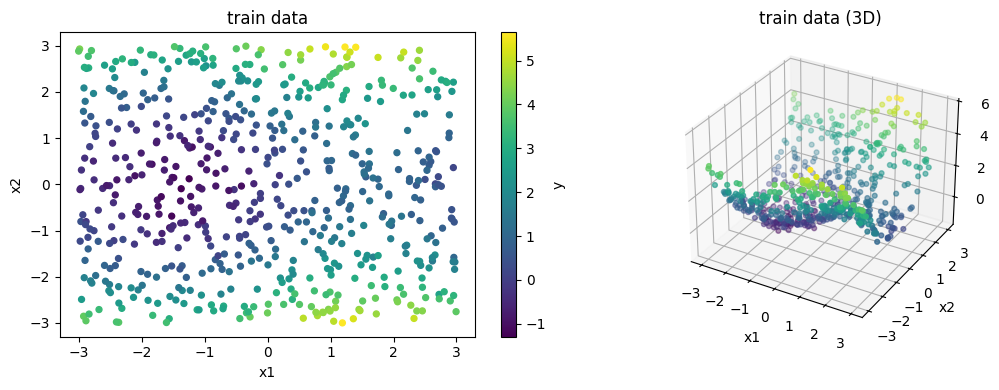

In [2]:
#(a) data visualization
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="viridis", s=18)
ax[0].set(title="train data", xlabel="x1", ylabel="x2")
plt.colorbar(sc, ax=ax[0], label="y")
ax[1].remove()
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.scatter(X_tr[:, 0], X_tr[:, 1], y_tr, c=y_tr, cmap="viridis", s=12)
ax3.set(title="train data (3D)", xlabel="x1", ylabel="x2", zlabel="y")
plt.tight_layout()
plt.show()

best sigma: 5.4556 val MSE: 0.0362


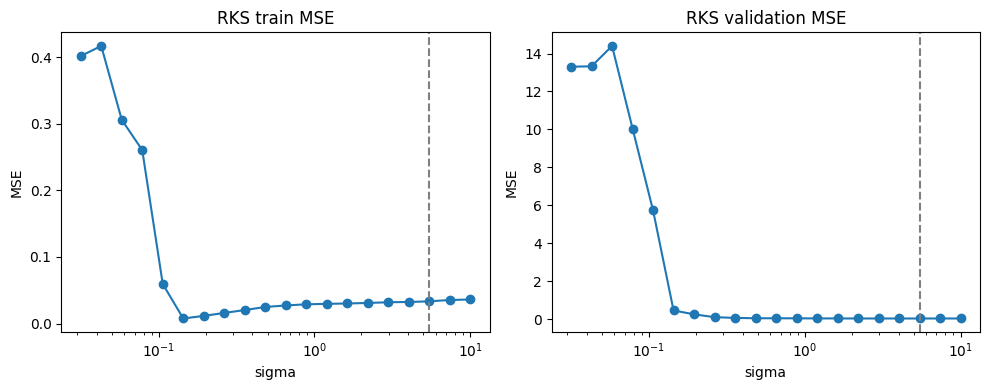

In [3]:
#(b) RKS with ridge regression
class RKS:
    def __init__(self, D=500, sigma=1.0, ridge_lambda=1e-3, seed=0):
        self.D, self.sigma, self.lam = D, sigma, ridge_lambda
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 1 / sigma, size=(2, D // 2))
        self.b = rng.uniform(0, 2 * np.pi, size=D // 2)

    def _features(self, X):
        P = X @ self.W + self.b
        return np.hstack([np.sin(P), np.cos(P), np.ones((len(X), 1))])

    def fit(self, X, y):
        Z = self._features(X)
        reg = self.lam * np.eye(Z.shape[1])
        reg[-1, -1] = 0
        self.coef_ = np.linalg.solve(Z.T @ Z + reg, Z.T @ y)
        return self

    def predict(self, X):
        return self._features(X) @ self.coef_

#sweep sigma
sigmas = np.logspace(-1.5, 1, 20)
rks_tr, rks_va = [], []
for s in sigmas:
    m = RKS(D=500, sigma=s, ridge_lambda=1e-3).fit(X_tr, y_tr)
    rks_tr.append(mse(m.predict(X_tr), y_tr))
    rks_va.append(mse(m.predict(X_va), y_va))
best_sigma = sigmas[int(np.argmin(rks_va))]
print("best sigma:", round(best_sigma, 4), "val MSE:", round(min(rks_va), 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, v, name in zip(ax, (rks_tr, rks_va), ("train", "validation")):
    a.semilogx(sigmas, v, "o-")
    a.axvline(best_sigma, color="gray", ls="--")
    a.set(title=f"RKS {name} MSE", xlabel="sigma", ylabel="MSE")
plt.tight_layout()
plt.show()

best hidden dim: 64 val MSE: 0.0403


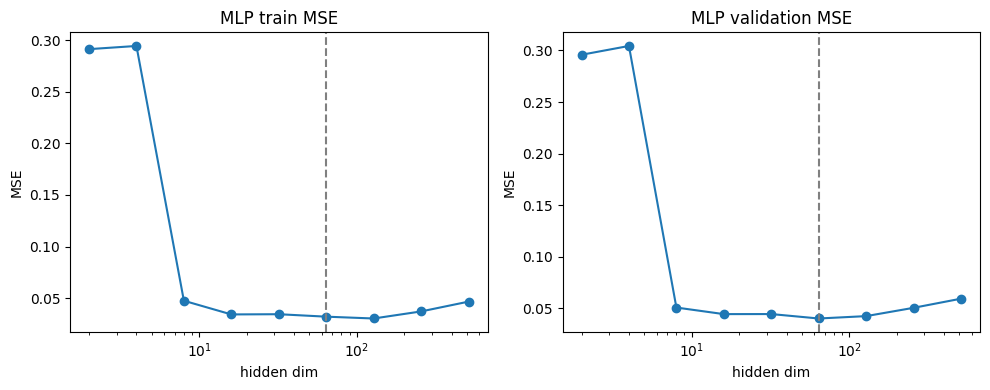

In [4]:
#(c) 1-hidden-layer MLP
class MLP(nn.Module):
    def __init__(self, d_in=2, d_hidden=128, lr=1e-2, batch_size=64, epochs=300):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, 1))
        self.lr, self.bs, self.epochs = lr, batch_size, epochs
        self.to(device)

    def forward(self, X):
        return self.net(X).squeeze(-1)

    def fit(self, X, y):
        X = torch.tensor(X, dtype=torch.float32, device=device)
        y = torch.tensor(y, dtype=torch.float32, device=device)
        opt = torch.optim.Adam(self.parameters(), lr=self.lr)
        for _ in range(self.epochs):
            perm = torch.randperm(len(X), device=device)
            for i in range(0, len(X), self.bs):
                idx = perm[i:i + self.bs]
                opt.zero_grad()
                nn.functional.mse_loss(self(X[idx]), y[idx]).backward()
                opt.step()
        return self

    def predict(self, X):
        with torch.no_grad():
            return self(torch.tensor(X, dtype=torch.float32, device=device)).cpu().numpy()

#sweep hidden dimension
dims = [2, 4, 8, 16, 32, 64, 128, 256, 512]
mlp_tr, mlp_va = [], []
for d in dims:
    torch.manual_seed(0)
    m = MLP(d_hidden=d).fit(X_tr, y_tr)
    mlp_tr.append(mse(m.predict(X_tr), y_tr))
    mlp_va.append(mse(m.predict(X_va), y_va))
best_dim = dims[int(np.argmin(mlp_va))]
print("best hidden dim:", best_dim, "val MSE:", round(min(mlp_va), 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, v, name in zip(ax, (mlp_tr, mlp_va), ("train", "validation")):
    a.semilogx(dims, v, "o-")
    a.axvline(best_dim, color="gray", ls="--")
    a.set(title=f"MLP {name} MSE", xlabel="hidden dim", ylabel="MSE")
plt.tight_layout()
plt.show()

In [5]:
#(d) refit best models, validation MSE, test predictions
rks = RKS(D=500, sigma=best_sigma, ridge_lambda=1e-3).fit(X_tr, y_tr)
torch.manual_seed(0)
mlp = MLP(d_hidden=best_dim).fit(X_tr, y_tr)
print("RKS val MSE:", round(mse(rks.predict(X_va), y_va), 4))
print("MLP val MSE:", round(mse(mlp.predict(X_va), y_va), 4))

np.savetxt("rks_test_predictions.csv", rks.predict(X_test), delimiter=",")
np.savetxt("mlp_test_predictions.csv", mlp.predict(X_test), delimiter=",")

RKS val MSE: 0.0362
MLP val MSE: 0.0403


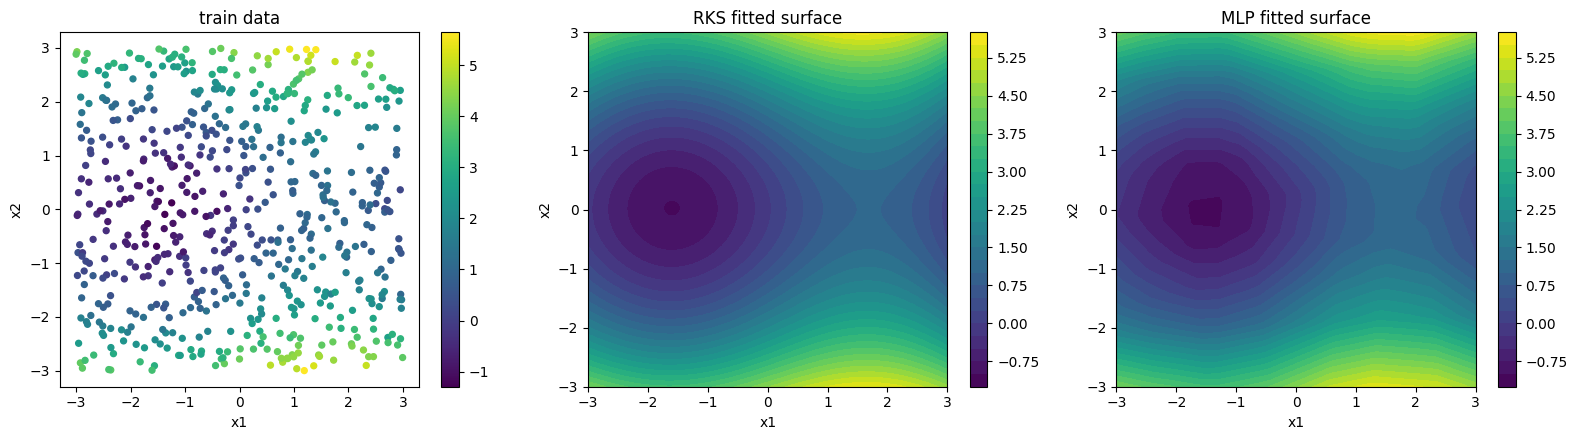

In [6]:
#fitted surfaces vs. training data
g = np.linspace(-3, 3, 200)
G1, G2 = np.meshgrid(g, g)
grid = np.stack([G1.ravel(), G2.ravel()], axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sc = ax[0].scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="viridis", s=18)
ax[0].set_title("train data")
plt.colorbar(sc, ax=ax[0])
for a, m, name in zip(ax[1:], (rks, mlp), ("RKS", "MLP")):
    cs = a.contourf(G1, G2, m.predict(grid).reshape(200, 200), levels=30)
    a.set_title(f"{name} fitted surface")
    plt.colorbar(cs, ax=a)
for a in ax:
    a.set(xlabel="x1", ylabel="x2")
plt.tight_layout()
plt.show()